# Analisis Asosiasi Gender pada Jabatan Profesional KBJI 2014 Menggunakan IndoBERT dan Log-Probability Bias Score

Data berisi nama jabatan profesional KBJI 2014 pada enam Subgolongan Pokok kode 21–26 dan didominasi frasa multi-kata. IndoBERT digunakan agar jabatan diproses dalam konteks kalimat. LPBS mengukur perubahan kecenderungan masked language model dalam memprediksi istilah gender ketika informasi jabatan ditambahkan. fastText sebelumnya memakai rata-rata vektor token, sedangkan pendekatan ini memakai probabilitas token kontekstual.

Hasil dibatasi sebagai asosiasi model intrinsik, bukan fakta sosial, komposisi tenaga kerja, diskriminasi, perilaku manusia, atau salinan resmi klasifikasi KBJI.


In [1]:
import hashlib
import json
import math
import platform
import random
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import scipy
import torch
import transformers
from IPython.display import Markdown, display
from scipy.stats import kruskal, mannwhitneyu, spearmanr
from statsmodels.stats.multitest import multipletests
from tqdm.auto import tqdm
from transformers import AutoModelForMaskedLM, AutoTokenizer

RANDOM_SEED = 42
BOOTSTRAP_REPETITIONS = 5000
MODEL_NAME = "indobenchmark/indobert-base-p1"
MODEL_REVISION_REQUESTED = "main"
INFERENCE_BATCH_SIZE = 8
MAX_SEQUENCE_LENGTH = 128
ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
TIME_START = time.time()
TIME_START_ISO = time.strftime("%Y-%m-%dT%H:%M:%S%z")
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print({"python": platform.python_version(), "pytorch": torch.__version__, "transformers": transformers.__version__, "scipy": scipy.__version__, "device": str(device), "cuda_available": torch.cuda.is_available(), "random_seed": RANDOM_SEED, "model": MODEL_NAME, "revision_requested": MODEL_REVISION_REQUESTED, "time_start": TIME_START_ISO})


C:\Users\Wiraditya\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'python': '3.14.0', 'pytorch': '2.12.1+cpu', 'transformers': '4.57.6', 'scipy': '1.16.3', 'device': 'cpu', 'cuda_available': False, 'random_seed': 42, 'model': 'indobenchmark/indobert-base-p1', 'revision_requested': 'main', 'time_start': '2026-09-08T19:38:26+0700'}


## 3. Membaca data final

Notebook membaca CSV hasil pemrosesan yang sudah final. PDF tidak diekstrak ulang, nama tidak dibersihkan ulang, dan file input tidak ditimpa. Data analysis dipakai untuk skor utama; data all dipakai untuk deskripsi seluruh nama jabatan.


In [2]:
required_columns = {"occupation_code", "occupation_name_raw", "occupation_text", "submajor_group_code", "group_code"}
analysis_candidates = [DATA_DIR / "test_v3_kbji_profesional_analysis.csv", DATA_DIR / "test_v2_kbji_profesional_analysis.csv"]
all_candidates = [DATA_DIR / "test_v3_kbji_profesional_all.csv", DATA_DIR / "test_v2_kbji_profesional_all.csv"]
analysis_path = next((p for p in analysis_candidates if p.exists()), None)
all_path = next((p for p in all_candidates if p.exists()), None)
gender_path = DATA_DIR / "test_v3_istilah_gender.csv"
assert analysis_path and all_path and gender_path.exists()
dtype_map = {"occupation_code": str, "submajor_group_code": str, "group_code": str, "subgroup_code": str}
df_analysis = pd.read_csv(analysis_path, dtype=dtype_map)
df_all = pd.read_csv(all_path, dtype=dtype_map)
gender_csv = pd.read_csv(gender_path)
assert required_columns.issubset(df_analysis.columns) and required_columns.issubset(df_all.columns)
assert {"pair_id", "male_term", "female_term", "lexical_category", "register", "validation_status", "include_baseline", "notes"}.issubset(gender_csv.columns)
input_hashes_before = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [analysis_path, all_path, gender_path]}
print("CSV analisis:", analysis_path, "| CSV lengkap:", all_path)
print("Jumlah analisis:", len(df_analysis), "| seluruh nama:", len(df_all), "| kolom:", len(df_analysis.columns))


CSV analisis: E:\SEMESTER 7 (SKRIPSI)\skripsi-weat\data\test_v3_kbji_profesional_analysis.csv | CSV lengkap: E:\SEMESTER 7 (SKRIPSI)\skripsi-weat\data\test_v3_kbji_profesional_all.csv
Jumlah analisis: 415 | seluruh nama: 501 | kolom: 30


In [3]:
display(df_analysis.head())
display(df_analysis.sample(min(5, len(df_analysis)), random_state=RANDOM_SEED))
df_analysis.info()
display(pd.DataFrame({"baris": [len(df_analysis)], "kolom": [len(df_analysis.columns)], "duplikat_baris": [int(df_analysis.duplicated().sum())]}))
display(df_analysis.isna().sum().rename("jumlah_kosong").to_frame())
allowed_groups = {"21", "22", "23", "24", "25", "26"}
assert set(df_analysis["submajor_group_code"].dropna().astype(str)).issubset(allowed_groups)
assert set(df_analysis["submajor_group_code"].dropna().astype(str)) == allowed_groups
display(df_analysis.groupby(["submajor_group_code", "submajor_group_name"]).size().rename("jumlah_jabatan").reset_index())
display(df_analysis.groupby("submajor_group_code", group_keys=False).head(3)[["occupation_code", "occupation_name_raw", "submajor_group_code"]])
df_all["observed_token_count"] = df_all["occupation_text"].fillna("").str.split().str.len()
df_all["observed_multiword"] = df_all["observed_token_count"] > 1
display(df_all[["occupation_name_raw", "occupation_text", "observed_token_count"]].head(10))
display(df_all["observed_token_count"].describe().to_frame("nilai"))
display(df_all["observed_multiword"].value_counts(normalize=True).rename("proporsi").to_frame())
print("Proporsi multi-kata:", round(float(df_all["observed_multiword"].mean()), 4))


,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,...,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_text,name_nonempty,include_analysis,exclusion_reason
0,2111.01,Ahli Fisika (Umum),161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,NaN
1,2111.02,Ahli Fisika Nuklir,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,NaN
2,2111.03,Ahli Fisika Mekanika,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,NaN
3,2111.04,Ahli Fisika Panas,161,121,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,NaN
4,2111.05,Ahli Fisika Sinar,162,122,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,...,False,False,False,True,True,False,False,True,True,NaN


,occupation_code,occupation_name_raw,source_page_pdf,source_page_printed,major_group_code,major_group_name,submajor_group_code,submajor_group_name,group_code,group_name,...,is_duplicate,is_residual,contains_gender_attribute,hierarchy_complete,hierarchy_prefix_match,code_name_conflict,duplicate_occupation_text,name_nonempty,include_analysis,exclusion_reason
55,2133.07,Konsultan Lingkungan,181,141,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,213,Ahli Ilmu Pengetahuan Hayati,...,False,False,False,True,True,False,False,True,True,NaN
140,2212.01,Dokter Spesialis Anestesi,216,176,2,Profesional,22,Profesional kesehatan,221,Dokter Medis,...,False,False,False,True,True,False,False,True,True,NaN
175,2250.02,Dokter Hewan Kesehatan Masyarakat,230,190,2,Profesional,22,Profesional kesehatan,225,Dokter Hewan,...,False,False,False,True,True,False,False,True,True,NaN
56,2141.01,Ahli Teknik Efisiensi Industri,182,142,2,Profesional,21,Ahli ilmu pengetahuan dan teknik,214,Ahli Teknik (Selain Ahli Teknologi Elektro),...,False,False,False,True,True,False,False,True,True,NaN
341,2635.01,Konselor Kecanduan,306,266,2,Profesional,26,"Profesional hukum, sosial dan budaya",263,Profesional Sosial dan Keagamaan,...,False,False,False,True,True,False,False,True,True,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 415 entries, 0 to 414
Data columns (total 30 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   occupation_code                        415 non-null    object 
 1   occupation_name_raw                    415 non-null    object 
 2   source_page_pdf                        415 non-null    int64  
 3   source_page_printed                    415 non-null    int64  
 4   major_group_code                       415 non-null    int64  
 5   major_group_name                       415 non-null    object 
 6   submajor_group_code                    415 non-null    object 
 7   submajor_group_name                    415 non-null    object 
 8   group_code                             415 non-null    object 
 9   group_name                             415 non-null    object 
 10  subgroup_code                          415 non-null    object 
 11  subgro

,baris,kolom,duplikat_baris
0,415,30,0


,jumlah_kosong
occupation_code,0
occupation_name_raw,0
source_page_pdf,0
source_page_printed,0
major_group_code,0
major_group_name,0
submajor_group_code,0
submajor_group_name,0
group_code,0
group_name,0


...

,occupation_code,occupation_name_raw,submajor_group_code
0,2111.01,Ahli Fisika (Umum),21
1,2111.02,Ahli Fisika Nuklir,21
2,2111.03,Ahli Fisika Mekanika,21
138,2211.01,Dokter Umum,22
139,2211.02,Dokter Keluarga,22
140,2212.01,Dokter Spesialis Anestesi,22
212,2310.01,Dosen Ilmu Fisika,23
213,2310.02,Dosen Ilmu Teknik dan Arsitektur,23
214,2310.03,Dosen Ilmu Kedokteran dan Ilmu Hayati,23
254,2411.01,Akuntan,24


,occupation_name_raw,occupation_text,observed_token_count
0,Ahli Fisika (Umum),ahli fisika,2
1,Ahli Fisika Nuklir,ahli fisika nuklir,3
2,Ahli Fisika Mekanika,ahli fisika mekanika,3
3,Ahli Fisika Panas,ahli fisika panas,3
4,Ahli Fisika Sinar,ahli fisika sinar,3
5,Ahli Fisika Suara,ahli fisika suara,3
6,Ahli Fisika Listrik Dan Magnit,ahli fisika listrik dan magnit,5
7,Ahli Fisika Elektronika,ahli fisika elektronika,3
8,Ahli Fisika Medis,ahli fisika medis,3
9,Ahli Astronomi,ahli astronomi,2


,nilai
count,501.000000
mean,3.089820
std,1.503967
min,1.000000
25%,2.000000
50%,3.000000
75%,4.000000
max,9.000000


,proporsi
observed_multiword,
True,0.916168
False,0.083832


Proporsi multi-kata: 0.9162


## 4. Memuat IndoBERT masked language model

IndoBERT dimuat dengan AutoTokenizer dan AutoModelForMaskedLM, dipindahkan ke device yang tersedia, dan dijalankan dalam mode evaluasi. Notebook tidak memakai embedding CLS dan tidak menerapkan WEAT pada CLS.


In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION_REQUESTED)
model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME, revision=MODEL_REVISION_REQUESTED).to(device)
model.eval()
MODEL_REVISION = getattr(model.config, "_commit_hash", None) or MODEL_REVISION_REQUESTED
model_parameter_count = sum(p.numel() for p in model.parameters())
print({"model_name": MODEL_NAME, "revision": MODEL_REVISION, "vocabulary_size": tokenizer.vocab_size, "mask_token": tokenizer.mask_token, "mask_token_id": tokenizer.mask_token_id, "parameter_count": model_parameter_count, "device": str(device), "source": "Hugging Face Transformers"})
assert tokenizer.mask_token_id is not None


Some weights of BertForMaskedLM were not initialized from the model checkpoint at indobenchmark/indobert-base-p1 and are newly initialized: ['cls.predictions.bias', 'cls.predictions.decoder.bias', 'cls.predictions.transform.LayerNorm.bias', 'cls.predictions.transform.LayerNorm.weight', 'cls.predictions.transform.dense.bias', 'cls.predictions.transform.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{'model_name': 'indobenchmark/indobert-base-p1', 'revision': 'c2cd0b51ddce6580eb35263b39b0a1e5fb0a39e2', 'vocabulary_size': 30521, 'mask_token': '[MASK]', 'mask_token_id': 4, 'parameter_count': 124492880, 'device': 'cpu', 'source': 'Hugging Face Transformers'}


## 5. Audit tokenisasi istilah gender

Kondisi utama ditetapkan a priori sebagai pria–wanita. Kondisi sensitivitas adalah laki-laki–perempuan. Jika kandidat terdiri dari beberapa subtoken, skor dihitung dengan pseudo-log-likelihood: setiap subtoken disembunyikan bergantian dan log-probability token aslinya dijumlahkan, lalu dinormalisasi berdasarkan jumlah subtoken.


In [5]:
gender_pair_specs = [
    {"gender_pair": "pria-wanita", "male_term": "pria", "female_term": "wanita", "condition": "utama"},
    {"gender_pair": "laki-laki-perempuan", "male_term": "laki-laki", "female_term": "perempuan", "condition": "sensitivitas leksikal"},
]
tokenization_rows = []
for spec in gender_pair_specs:
    for gender, term in [("laki-laki", spec["male_term"]), ("perempuan", spec["female_term"])]:
        tokens = tokenizer.tokenize(term)
        ids = tokenizer.convert_tokens_to_ids(tokens)
        tokenization_rows.append({"gender_pair": spec["gender_pair"], "gender": gender, "term": term, "token_ids": json.dumps(ids), "tokens": " | ".join(tokens), "token_count": len(tokens), "status": "satu token" if len(tokens) == 1 else "pseudo-log-likelihood multi-token"})
tokenization_audit = pd.DataFrame(tokenization_rows)
display(tokenization_audit)


,gender_pair,gender,term,token_ids,tokens,token_count,status
0,pria-wanita,laki-laki,pria,[1380],pria,1,satu token
1,pria-wanita,perempuan,wanita,[922],wanita,1,satu token
2,laki-laki-perempuan,laki-laki,laki-laki,"[7041, 30469, 7041]",laki | - | laki,3,pseudo-log-likelihood multi-token
3,laki-laki-perempuan,perempuan,perempuan,[1747],perempuan,1,satu token


## 6. Penyusunan template netral

Empat template jabatan dan baseline ditetapkan sebelum melihat hasil. Validasi memeriksa satu mask, penyisipan occupation, panjang token, dan teks yang tidak kosong.


In [6]:
template_specs = [
    {"template_id": "T1", "job": "Seorang [MASK] bekerja sebagai {occupation}.", "baseline": "Seorang [MASK] bekerja."},
    {"template_id": "T2", "job": "{occupation} tersebut adalah seorang [MASK].", "baseline": "Orang tersebut adalah seorang [MASK]."},
    {"template_id": "T3", "job": "Pekerjaan sebagai {occupation} dilakukan oleh seorang [MASK].", "baseline": "Pekerjaan tersebut dilakukan oleh seorang [MASK]."},
    {"template_id": "T4", "job": "Profesi {occupation} dijalankan oleh seorang [MASK].", "baseline": "Profesi tersebut dijalankan oleh seorang [MASK]."},
]
template_rows, example_rows = [], []
for spec in template_specs:
    example_rows.extend({"template_id": spec["template_id"], "occupation": row.occupation_text, "kalimat": spec["job"].format(occupation=row.occupation_text)} for row in df_analysis.head(3).itertuples(index=False))
    for kind in ["job", "baseline"]:
        rendered = spec[kind].format(occupation=df_analysis.iloc[0]["occupation_text"])
        length = len(tokenizer(rendered, add_special_tokens=True, truncation=False)["input_ids"])
        template_rows.append({"template_id": spec["template_id"], "kind": kind, "mask_count": rendered.count(tokenizer.mask_token), "token_length": length, "within_model_limit": length <= MAX_SEQUENCE_LENGTH, "occupation_inserted": kind == "baseline" or "{occupation}" in spec[kind], "status": "valid" if rendered.strip() and rendered.count(tokenizer.mask_token) == 1 and length <= MAX_SEQUENCE_LENGTH else "invalid"})
template_validation = pd.DataFrame(template_rows)
display(template_validation)
display(pd.DataFrame(example_rows))
assert (template_validation["status"] == "valid").all()


,template_id,kind,mask_count,token_length,within_model_limit,occupation_inserted,status
0,T1,job,1,9,True,True,valid
1,T1,baseline,1,6,True,True,valid
2,T2,job,1,9,True,True,valid
3,T2,baseline,1,8,True,True,valid
4,T3,job,1,11,True,True,valid
5,T3,baseline,1,9,True,True,valid
6,T4,job,1,10,True,True,valid
7,T4,baseline,1,9,True,True,valid


,template_id,occupation,kalimat
0,T1,ahli fisika,Seorang [MASK] bekerja sebagai ahli fisika.
1,T1,ahli fisika nuklir,Seorang [MASK] bekerja sebagai ahli fisika nuk...
2,T1,ahli fisika mekanika,Seorang [MASK] bekerja sebagai ahli fisika mek...
3,T2,ahli fisika,ahli fisika tersebut adalah seorang [MASK].
4,T2,ahli fisika nuklir,ahli fisika nuklir tersebut adalah seorang [MA...
5,T2,ahli fisika mekanika,ahli fisika mekanika tersebut adalah seorang [...
6,T3,ahli fisika,Pekerjaan sebagai ahli fisika dilakukan oleh s...
7,T3,ahli fisika nuklir,Pekerjaan sebagai ahli fisika nuklir dilakukan...
8,T3,ahli fisika mekanika,Pekerjaan sebagai ahli fisika mekanika dilakuk...
9,T4,ahli fisika,Profesi ahli fisika dijalankan oleh seorang [M...


## 7. Perhitungan LPBS

Probabilitas dan log-probability mentah disimpan untuk jabatan dan baseline. Probabilitas kandidat multi-token dilaporkan sebagai exp dari log-probability rata-rata per subtoken; jumlah log-probability mentah juga dipertahankan dalam perhitungan internal.


In [7]:
def context_parts(template_text, occupation=None):
    rendered = template_text.format(occupation=occupation) if occupation is not None else template_text
    assert rendered.count("[MASK]") == 1
    return rendered.split("[MASK]")

def score_contexts(contexts, terms):
    ids_by_term = {term: tokenizer(term, add_special_tokens=False)["input_ids"] for term in terms}
    singles = [term for term in terms if len(ids_by_term[term]) == 1]
    multis = [term for term in terms if len(ids_by_term[term]) > 1]
    result = {term: {"raw_logprob": np.full(len(contexts), np.nan), "logprob": np.full(len(contexts), np.nan), "probability": np.full(len(contexts), np.nan), "token_count": len(ids_by_term[term])} for term in terms}
    single_ids = []
    for prefix, suffix in contexts:
        pids = tokenizer(prefix, add_special_tokens=False)["input_ids"]
        sids = tokenizer(suffix, add_special_tokens=False)["input_ids"]
        ids = tokenizer.build_inputs_with_special_tokens(pids + [tokenizer.mask_token_id] + sids)
        assert len(ids) <= MAX_SEQUENCE_LENGTH
        single_ids.append(ids)
    for start in tqdm(range(0, len(single_ids), INFERENCE_BATCH_SIZE), desc="single-token contexts"):
        batch_ids = single_ids[start:start + INFERENCE_BATCH_SIZE]
        batch = tokenizer.pad({"input_ids": batch_ids}, return_tensors="pt").to(device)
        with torch.no_grad():
            log_probs = torch.log_softmax(model(**batch).logits, dim=-1)
        for local, ids in enumerate(batch_ids):
            position = ids.index(tokenizer.mask_token_id)
            values = log_probs[local, position]
            for term in singles:
                raw = float(values[ids_by_term[term][0]].item())
                index = start + local
                result[term]["raw_logprob"][index] = raw
                result[term]["logprob"][index] = raw
                result[term]["probability"][index] = math.exp(raw)
    for term in multis:
        candidate = ids_by_term[term]
        tasks = []
        for index, (prefix, suffix) in enumerate(contexts):
            pids = tokenizer(prefix, add_special_tokens=False)["input_ids"]
            sids = tokenizer(suffix, add_special_tokens=False)["input_ids"]
            for position, token_id in enumerate(candidate):
                candidate_masked = candidate.copy()
                candidate_masked[position] = tokenizer.mask_token_id
                ids = tokenizer.build_inputs_with_special_tokens(pids + candidate_masked + sids)
                assert len(ids) <= MAX_SEQUENCE_LENGTH
                tasks.append((index, token_id, ids))
        raw_sums = np.zeros(len(contexts))
        for start in tqdm(range(0, len(tasks), INFERENCE_BATCH_SIZE), desc=f"PLL {term}"):
            task_batch = tasks[start:start + INFERENCE_BATCH_SIZE]
            batch_ids = [task[2] for task in task_batch]
            batch = tokenizer.pad({"input_ids": batch_ids}, return_tensors="pt").to(device)
            with torch.no_grad():
                log_probs = torch.log_softmax(model(**batch).logits, dim=-1)
            for local, (_, token_id, ids) in enumerate(task_batch):
                position = ids.index(tokenizer.mask_token_id)
                raw_sums[task_batch[local][0]] += float(log_probs[local, position, token_id].item())
        normalized = raw_sums / len(candidate)
        result[term]["raw_logprob"] = raw_sums
        result[term]["logprob"] = normalized
        result[term]["probability"] = np.exp(normalized)
    return result

score_terms = ["pria", "wanita", "laki-laki", "perempuan"]
job_contexts, context_keys = [], []
for row in df_analysis.itertuples(index=False):
    for spec in template_specs:
        prefix, suffix = context_parts(spec["job"], row.occupation_text)
        job_contexts.append((prefix, suffix))
        context_keys.append((row.occupation_code, spec["template_id"]))
job_scores = score_contexts(job_contexts, score_terms)
baseline_scores = {}
for spec in template_specs:
    prefix, suffix = context_parts(spec["baseline"])
    baseline_scores[spec["template_id"]] = score_contexts([(prefix, suffix)], score_terms)


single-token contexts:   0%|          | 0/208 [00:00<?, ?it/s]

You're using a BertTokenizerFast tokenizer. Please note that with a fast tokenizer, using the `__call__` method is faster than using a method to encode the text followed by a call to the `pad` method to get a padded encoding.


single-token contexts:   0%|          | 1/208 [00:00<00:23,  8.67it/s]

single-token contexts:   1%|          | 2/208 [00:00<00:23,  8.66it/s]

single-token contexts:   1%|▏         | 3/208 [00:00<00:24,  8.32it/s]

...

PLL laki-laki: 100%|██████████| 1/1 [00:00<00:00, 17.88it/s]

single-token contexts:   0%|          | 0/1 [00:00<?, ?it/s]

single-token contexts: 100%|██████████| 1/1 [00:00<00:00, 23.52it/s]

PLL laki-laki:   0%|          | 0/1 [00:00<?, ?it/s]

PLL laki-laki: 100%|██████████| 1/1 [00:00<00:00, 17.27it/s]

In [8]:
long_rows = []
for index, (occupation_code, template_id) in enumerate(context_keys):
    source = df_analysis.loc[df_analysis["occupation_code"].eq(occupation_code)].iloc[0]
    base = baseline_scores[template_id]
    for spec in gender_pair_specs:
        male, female = spec["male_term"], spec["female_term"]
        male_job, female_job = job_scores[male]["logprob"][index], job_scores[female]["logprob"][index]
        male_base, female_base = base[male]["logprob"][0], base[female]["logprob"][0]
        male_change, female_change = male_job - male_base, female_job - female_base
        long_rows.append({"occupation_id": source["occupation_code"], "occupation_code": source["occupation_code"], "occupation_name": source["occupation_name_raw"], "occupation_name_raw": source["occupation_name_raw"], "occupation_text": source["occupation_text"], "kbji_group_code": source["submajor_group_code"], "kbji_group_name": source["submajor_group_name"], "kbji_detail_code": source["group_code"], "kbji_detail_name": source["group_name"], "template_id": template_id, "gender_pair": spec["gender_pair"], "condition": spec["condition"], "male_term": male, "female_term": female, "male_token_count": len(tokenizer.tokenize(male)), "female_token_count": len(tokenizer.tokenize(female)), "male_logprob_job_raw": job_scores[male]["raw_logprob"][index], "male_logprob_job": male_job, "female_logprob_job_raw": job_scores[female]["raw_logprob"][index], "female_logprob_job": female_job, "male_logprob_baseline_raw": base[male]["raw_logprob"][0], "male_logprob_baseline": male_base, "female_logprob_baseline_raw": base[female]["raw_logprob"][0], "female_logprob_baseline": female_base, "male_probability_job_raw": math.exp(job_scores[male]["raw_logprob"][index]), "male_probability_job": job_scores[male]["probability"][index], "female_probability_job_raw": math.exp(job_scores[female]["raw_logprob"][index]), "female_probability_job": job_scores[female]["probability"][index], "male_probability_baseline_raw": math.exp(base[male]["raw_logprob"][0]), "male_probability_baseline": base[male]["probability"][0], "female_probability_baseline_raw": math.exp(base[female]["raw_logprob"][0]), "female_probability_baseline": base[female]["probability"][0], "male_logprob_change": male_change, "female_logprob_change": female_change, "lpbs_score": male_change - female_change})
lpbs_scores_long = pd.DataFrame(long_rows)
display(lpbs_scores_long.head())


,occupation_id,occupation_code,occupation_name,occupation_name_raw,occupation_text,kbji_group_code,kbji_group_name,kbji_detail_code,kbji_detail_name,template_id,...,male_probability_job,female_probability_job_raw,female_probability_job,male_probability_baseline_raw,male_probability_baseline,female_probability_baseline_raw,female_probability_baseline,male_logprob_change,female_logprob_change,lpbs_score
0,2111.01,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,...,0.000033,0.000035,0.000035,4.483841e-05,0.000045,0.000037,0.000037,-0.301409,-0.068336,-0.233073
1,2111.01,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T1,...,0.000025,0.000035,0.000035,1.284341e-14,0.000023,0.000052,0.000052,0.083543,-0.375112,0.458654
2,2111.01,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T2,...,0.000011,0.000018,0.000018,9.422999e-06,0.000009,0.000018,0.000018,0.116037,0.034270,0.081767
3,2111.01,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T2,...,0.000029,0.000023,0.000023,2.757280e-14,0.000030,0.000024,0.000024,-0.045505,-0.037324,-0.008181
4,2111.01,2111.01,Ahli Fisika (Umum),Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,T3,...,0.000007,0.000015,0.000015,6.947196e-06,0.000007,0.000012,0.000012,-0.021009,0.246425,-0.267434


LPBS positif berarti informasi jabatan meningkatkan perbedaan relatif ke istilah laki-laki; LPBS negatif berarti relatif ke istilah perempuan. Skor ini bukan predikat bahwa jabatan tersebut cocok untuk gender tertentu.


In [9]:
main_long = lpbs_scores_long[lpbs_scores_long["condition"].eq("utama")].copy()
main_long["direction"] = np.select([main_long["lpbs_score"] > 0, main_long["lpbs_score"] < 0], ["positif", "negatif"], default="nol")
qc_intermediate = pd.DataFrame([
    {"check": "jumlah baris utama", "status": len(main_long) == len(df_analysis) * 4, "observed": len(main_long)},
    {"check": "kelompok 21-26", "status": set(main_long["kbji_group_code"]) == allowed_groups, "observed": sorted(main_long["kbji_group_code"].unique())},
    {"check": "angka finite", "status": bool(np.isfinite(lpbs_scores_long.select_dtypes(include=np.number).to_numpy()).all()), "observed": int(lpbs_scores_long.isna().sum().sum())},
])
display(qc_intermediate)
assert qc_intermediate["status"].all()


,check,status,observed
0,jumlah baris utama,True,1660
1,kelompok 21-26,True,"[21, 22, 23, 24, 25, 26]"
2,angka finite,True,0


## 9. Agregasi skor per jabatan

Median lintas-template menjadi agregat utama. Rata-rata, median, simpangan baku, IQR, rentang, proporsi tanda, dan agreement tanda tetap disimpan agar variasi konteks dapat diaudit.


In [10]:
group_keys = ["occupation_code", "occupation_name_raw", "occupation_text", "kbji_group_code", "kbji_group_name", "kbji_detail_code", "kbji_detail_name"]
occupation_summary = main_long.groupby(group_keys, as_index=False).agg(valid_template_count=("lpbs_score", "count"), mean_lpbs=("lpbs_score", "mean"), median_lpbs=("lpbs_score", "median"), std_lpbs=("lpbs_score", "std"), minimum_lpbs=("lpbs_score", "min"), maximum_lpbs=("lpbs_score", "max"), positive_proportion=("lpbs_score", lambda x: (x > 0).mean()), negative_proportion=("lpbs_score", lambda x: (x < 0).mean()))
quartiles = main_long.groupby("occupation_code")["lpbs_score"].quantile([.25, .75]).unstack()
occupation_summary["iqr_lpbs"] = occupation_summary["occupation_code"].map(quartiles[.75] - quartiles[.25])
sign_matrix = main_long.pivot(index="occupation_code", columns="template_id", values="lpbs_score")
sign_stats = pd.DataFrame({
    "occupation_code": sign_matrix.index,
    "sign_agreement": sign_matrix.apply(lambda x: max((x > 0).sum(), (x < 0).sum(), (x == 0).sum()) / len(x), axis=1).to_numpy(),
    "sign_change_count": sign_matrix.apply(lambda x: int((np.sign(x) != np.sign(x.median())).sum()), axis=1).to_numpy(),
})
occupation_summary = occupation_summary.merge(sign_stats, on="occupation_code", how="left", validate="one_to_one")
occupation_summary["score_range"] = occupation_summary["maximum_lpbs"] - occupation_summary["minimum_lpbs"]
occupation_summary["direction_descriptive"] = np.select([occupation_summary["median_lpbs"] > 0, occupation_summary["median_lpbs"] < 0], ["positif", "negatif"], default="nol")
display(occupation_summary.head())
display(occupation_summary["direction_descriptive"].value_counts().rename("jumlah_jabatan").to_frame())


,occupation_code,occupation_name_raw,occupation_text,kbji_group_code,kbji_group_name,kbji_detail_code,kbji_detail_name,valid_template_count,mean_lpbs,median_lpbs,std_lpbs,minimum_lpbs,maximum_lpbs,positive_proportion,negative_proportion,iqr_lpbs,sign_agreement,sign_change_count,score_range,direction_descriptive
0,2111.01,Ahli Fisika (Umum),ahli fisika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,4,-0.166574,-0.240314,0.166159,-0.267434,0.081767,0.25,0.75,0.098161,0.75,1,0.349201,negatif
1,2111.02,Ahli Fisika Nuklir,ahli fisika nuklir,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,4,-0.204611,-0.261421,0.165186,-0.331009,0.035409,0.25,0.75,0.136837,0.75,1,0.366418,negatif
2,2111.03,Ahli Fisika Mekanika,ahli fisika mekanika,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,4,-0.183283,-0.256416,0.227228,-0.367175,0.146873,0.25,0.75,0.167936,0.75,1,0.514049,negatif
3,2111.04,Ahli Fisika Panas,ahli fisika panas,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,4,-0.257829,-0.241546,0.207720,-0.525900,-0.022326,0.00,1.00,0.168176,1.00,0,0.503574,negatif
4,2111.05,Ahli Fisika Sinar,ahli fisika sinar,21,Ahli ilmu pengetahuan dan teknik,211,Ahli Fisika dan Ilmu Bumi,4,-0.169832,-0.184282,0.281635,-0.496816,0.186053,0.25,0.75,0.237497,0.75,1,0.682869,negatif


,jumlah_jabatan
direction_descriptive,
positif,214
negatif,201


## 10. Enam kelompok KBJI dan cluster bootstrap

Kode 21–26 adalah unit utama. Interval percentile 95% memakai median dan 5.000 pengulangan. Jika kode tiga digit tersedia, baris di-resampling berdasarkan cluster kode tersebut.


In [11]:
group_rows = []
rng_bootstrap = np.random.default_rng(RANDOM_SEED)
for group in sorted(allowed_groups):
    subset = occupation_summary[occupation_summary["kbji_group_code"].astype(str).eq(group)].copy()
    clusters = subset["kbji_detail_code"].dropna().astype(str).unique()
    values = []
    for _ in range(BOOTSTRAP_REPETITIONS):
        sampled = pd.concat([subset[subset["kbji_detail_code"].astype(str).eq(c)] for c in rng_bootstrap.choice(clusters, len(clusters), replace=True)], ignore_index=True)
        values.append(float(sampled["median_lpbs"].median()))
    group_rows.append({"kbji_group_code": group, "kbji_group_name": subset["kbji_group_name"].iloc[0], "n_occupation": len(subset), "n_cluster": len(clusters), "cluster_unit": "group_code tiga digit", "mean_lpbs": subset["median_lpbs"].mean(), "median_lpbs": subset["median_lpbs"].median(), "std_lpbs": subset["median_lpbs"].std(), "iqr_lpbs": subset["median_lpbs"].quantile(.75) - subset["median_lpbs"].quantile(.25), "minimum_lpbs": subset["median_lpbs"].min(), "maximum_lpbs": subset["median_lpbs"].max(), "positive_proportion": (subset["median_lpbs"] > 0).mean(), "negative_proportion": (subset["median_lpbs"] < 0).mean(), "ci95_lower": np.percentile(values, 2.5), "ci95_upper": np.percentile(values, 97.5)})
group_summary = pd.DataFrame(group_rows)
display(group_summary)
display(Markdown("Interval yang melintasi nol belum menetapkan arah kelompok; interval yang seluruhnya di atas atau di bawah nol menunjukkan kecenderungan relatif yang lebih konsisten."))


,kbji_group_code,kbji_group_name,n_occupation,n_cluster,cluster_unit,mean_lpbs,median_lpbs,std_lpbs,iqr_lpbs,minimum_lpbs,maximum_lpbs,positive_proportion,negative_proportion,ci95_lower,ci95_upper
0,21,Ahli ilmu pengetahuan dan teknik,138,6,group_code tiga digit,-0.070499,-0.083372,0.137034,0.166404,-0.374423,0.489350,0.311594,0.688406,-0.138988,0.011564
1,22,Profesional kesehatan,74,6,group_code tiga digit,0.062998,0.071097,0.112308,0.146294,-0.215280,0.423313,0.743243,0.256757,0.012421,0.117417
2,23,Profesional pendidikan,42,5,group_code tiga digit,-0.136245,-0.170362,0.121794,0.186397,-0.307469,0.213970,0.095238,0.904762,-0.250167,-0.080396
3,24,Profesional bisnis dan administrasi,29,3,group_code tiga digit,0.103423,0.109436,0.124791,0.151359,-0.179888,0.303463,0.862069,0.137931,0.073345,0.172112
4,25,Profesional teknologi informasi dan komunikasi,26,2,group_code tiga digit,0.046535,0.041871,0.102926,0.122722,-0.138803,0.261302,0.576923,0.423077,0.022860,0.057342
5,26,"Profesional hukum, sosial dan budaya",106,5,group_code tiga digit,0.105182,0.105296,0.171935,0.261823,-0.248936,0.578463,0.679245,0.320755,-0.056978,0.177950


Interval yang melintasi nol belum menetapkan arah kelompok; interval yang seluruhnya di atas atau di bawah nol menunjukkan kecenderungan relatif yang lebih konsisten.

## 11. Perbandingan antarkelompok

Kruskal–Wallis dan epsilon-squared adalah analisis inferensial eksploratif. Perbandingan pasangan hanya dilanjutkan bila omnibus memberi alasan eksploratif dan dikoreksi dengan Holm. Hierarki KBJI dapat membuat observasi tidak independen penuh.


In [12]:
arrays = [occupation_summary.loc[occupation_summary["kbji_group_code"].astype(str).eq(g), "median_lpbs"].to_numpy() for g in sorted(allowed_groups)]
kw = kruskal(*arrays)
epsilon_squared = max(0.0, (float(kw.statistic) - len(arrays) + 1) / (len(occupation_summary) - len(arrays)))
statistical_rows = [{"test": "Kruskal-Wallis", "comparison": "21 vs 22 vs 23 vs 24 vs 25 vs 26", "statistic": float(kw.statistic), "p_value": float(kw.pvalue), "adjusted_p_value": np.nan, "effect_size": epsilon_squared, "interpretation": "eksploratif"}]
if kw.pvalue < 0.05:
    pair_rows = []
    groups_sorted = sorted(allowed_groups)
    for i, a in enumerate(groups_sorted):
        for b in groups_sorted[i + 1:]:
            result = mannwhitneyu(occupation_summary.loc[occupation_summary["kbji_group_code"].astype(str).eq(a), "median_lpbs"], occupation_summary.loc[occupation_summary["kbji_group_code"].astype(str).eq(b), "median_lpbs"], alternative="two-sided")
            pair_rows.append({"test": "Mann-Whitney U", "comparison": f"{a} vs {b}", "statistic": float(result.statistic), "p_value": float(result.pvalue), "adjusted_p_value": np.nan, "effect_size": np.nan, "interpretation": "eksploratif; Holm"})
    for row, adj in zip(pair_rows, multipletests([x["p_value"] for x in pair_rows], method="holm")[1]):
        row["adjusted_p_value"] = float(adj)
    statistical_rows.extend(pair_rows)
statistical_tests = pd.DataFrame(statistical_rows)
display(statistical_tests)


,test,comparison,statistic,p_value,adjusted_p_value,effect_size,interpretation
0,Kruskal-Wallis,21 vs 22 vs 23 vs 24 vs 25 vs 26,125.019298,2.710616e-25,NaN,0.293446,eksploratif
1,Mann-Whitney U,21 vs 22,2176.000000,5.951746e-12,7.737269e-11,NaN,eksploratif; Holm
2,Mann-Whitney U,21 vs 23,3735.000000,4.667456e-03,3.267219e-02,NaN,eksploratif; Holm
3,Mann-Whitney U,21 vs 24,655.000000,1.313078e-08,1.313078e-07,NaN,eksploratif; Holm
4,Mann-Whitney U,21 vs 25,870.000000,3.213845e-05,2.571076e-04,NaN,eksploratif; Holm
5,Mann-Whitney U,21 vs 26,3151.000000,2.601548e-14,3.902323e-13,NaN,eksploratif; Holm
6,Mann-Whitney U,22 vs 23,2745.000000,7.980064e-12,9.576077e-11,NaN,eksploratif; Holm
7,Mann-Whitney U,22 vs 24,814.000000,5.802859e-02,2.901429e-01,NaN,eksploratif; Holm
8,Mann-Whitney U,22 vs 25,1073.000000,3.852084e-01,7.704167e-01,NaN,eksploratif; Holm
9,Mann-Whitney U,22 vs 26,3342.000000,9.203643e-02,3.681457e-01,NaN,eksploratif; Holm


## 12. Sensitivitas template

Dihitung median per template, korelasi Spearman, agreement tanda, jumlah sign flip, dan leave-one-template-out pada tingkat kelompok. Template tidak dibuang berdasarkan korelasi atau hasil uji.


In [13]:
template_summary = main_long.groupby("template_id", as_index=False).agg(n_occupation=("occupation_code", "count"), median_lpbs=("lpbs_score", "median"), mean_lpbs=("lpbs_score", "mean"), positive_proportion=("lpbs_score", lambda x: (x > 0).mean()), negative_proportion=("lpbs_score", lambda x: (x < 0).mean()))
template_stability_rows = []
for i, a in enumerate(sign_matrix.columns):
    for b in sign_matrix.columns[i + 1:]:
        pair = sign_matrix[[a, b]].dropna()
        template_stability_rows.append({"analysis": "pairwise_template", "template_a": a, "template_b": b, "kbji_group_code": "semua", "spearman": spearmanr(pair[a], pair[b]).statistic, "sign_agreement": float((np.sign(pair[a]) == np.sign(pair[b])).mean()), "sign_flip_count": int((np.sign(pair[a]) != np.sign(pair[b])).sum()), "median_absolute_difference": float((pair[a] - pair[b]).abs().median())})
for omitted in sign_matrix.columns:
    kept = sign_matrix.drop(columns=omitted).median(axis=1)
    for group in sorted(allowed_groups):
        codes = occupation_summary.loc[occupation_summary["kbji_group_code"].astype(str).eq(group), "occupation_code"]
        template_stability_rows.append({"analysis": "leave_one_template_out", "template_a": omitted, "template_b": "median_kept", "kbji_group_code": group, "spearman": np.nan, "sign_agreement": np.nan, "sign_flip_count": np.nan, "median_absolute_difference": float((kept.loc[codes].median() - occupation_summary.set_index("occupation_code").loc[codes, "median_lpbs"].median()))})
template_stability = pd.DataFrame(template_stability_rows)
display(template_summary)
display(template_stability)


,template_id,n_occupation,median_lpbs,mean_lpbs,positive_proportion,negative_proportion
0,T1,415,-0.128242,-0.124911,0.233735,0.766265
1,T2,415,0.188940,0.195989,0.869880,0.130120
2,T3,415,-0.032877,-0.040553,0.416867,0.583133
3,T4,415,0.032611,0.023924,0.561446,0.438554


,analysis,template_a,template_b,kbji_group_code,spearman,sign_agreement,sign_flip_count,median_absolute_difference
0,pairwise_template,T1,T2,semua,0.240381,0.310843,286.0,0.326440
1,pairwise_template,T1,T3,semua,0.344907,0.653012,144.0,0.151791
2,pairwise_template,T1,T4,semua,0.265102,0.551807,186.0,0.193122
3,pairwise_template,T2,T3,semua,0.774447,0.542169,190.0,0.251114
4,pairwise_template,T2,T4,semua,0.756862,0.677108,134.0,0.184608
5,pairwise_template,T3,T4,semua,0.920010,0.840964,66.0,0.071404
6,leave_one_template_out,T1,median_kept,21,NaN,NaN,NaN,0.040379
7,leave_one_template_out,T1,median_kept,22,NaN,NaN,NaN,0.022862
8,leave_one_template_out,T1,median_kept,23,NaN,NaN,NaN,-0.028090
9,leave_one_template_out,T1,median_kept,24,NaN,NaN,NaN,0.078417


## 13. Sensitivitas istilah gender

Kondisi utama pria–wanita dibandingkan dengan laki-laki–perempuan. Perbedaan hasil dibaca sebagai sensitivitas tokenisasi, frekuensi, register, penggunaan bahasa, dan korpus pelatihan, bukan sebagai dasar memilih pasangan paling signifikan.


In [14]:
lexical_wide = lpbs_scores_long.pivot_table(index=["occupation_code", "occupation_name_raw", "kbji_group_code", "kbji_group_name"], columns="condition", values="lpbs_score", aggfunc="median").reset_index()
lexical_wide["difference_sensitivity_minus_main"] = lexical_wide["sensitivitas leksikal"] - lexical_wide["utama"]
lexical_wide["absolute_difference"] = lexical_wide["difference_sensitivity_minus_main"].abs()
lexical_wide["same_direction"] = np.sign(lexical_wide["utama"]) == np.sign(lexical_wide["sensitivitas leksikal"])
lexical_group = lexical_wide.groupby("kbji_group_code", as_index=False).agg(main_median=("utama", "median"), sensitivity_median=("sensitivitas leksikal", "median"), median_absolute_difference=("absolute_difference", "median"), sign_agreement=("same_direction", "mean"), sign_flip_count=("same_direction", lambda x: int((~x).sum())))
lexical_stats = pd.DataFrame([{"metric": "Spearman skor jabatan", "value": spearmanr(lexical_wide["utama"], lexical_wide["sensitivitas leksikal"]).statistic}, {"metric": "perbedaan median", "value": lexical_wide["sensitivitas leksikal"].median() - lexical_wide["utama"].median()}, {"metric": "median absolute difference", "value": lexical_wide["absolute_difference"].median()}, {"metric": "sign agreement", "value": lexical_wide["same_direction"].mean()}, {"metric": "sign flip count", "value": int((~lexical_wide["same_direction"]).sum())}])
lexical_sensitivity = pd.concat([lexical_wide.assign(analysis="occupation"), lexical_group.assign(analysis="group"), lexical_stats.assign(analysis="overall")], ignore_index=True, sort=False)
display(lexical_stats)
display(lexical_group)


,metric,value
0,Spearman skor jabatan,0.246846
1,perbedaan median,0.058546
2,median absolute difference,0.163577
3,sign agreement,0.602410
4,sign flip count,165.000000


,kbji_group_code,main_median,sensitivity_median,median_absolute_difference,sign_agreement,sign_flip_count
0,21,-0.083372,0.055787,0.175656,0.485507,71
1,22,0.071097,0.068365,0.129380,0.689189,23
2,23,-0.170362,-0.090215,0.112386,0.761905,10
3,24,0.109436,0.270725,0.159142,0.862069,4
4,25,0.041871,0.087541,0.103394,0.653846,9
5,26,0.105296,0.132563,0.227920,0.547170,48


## 14. Perbandingan dengan baseline fastText/SC-WEAT

Baseline dibaca dari output fastText yang sudah ada jika kolomnya kompatibel. LPBS dan SC-WEAT berbeda skala; perbandingan dibatasi pada arah, peringkat, korelasi, dan agreement.


In [15]:
fasttext_path = ROOT / "outputs" / "test_v2_hasil_scweat.csv"
fasttext_comparison = pd.DataFrame()
fasttext_group_comparison = pd.DataFrame()
fasttext_message = "Baseline fastText dilewati: file tidak ditemukan."
if fasttext_path.exists():
    fasttext = pd.read_csv(fasttext_path, dtype={"occupation_code": str})
    if {"occupation_code", "scweat_effect_size"}.issubset(fasttext.columns):
        fasttext_comparison = occupation_summary[["occupation_code", "occupation_name_raw", "kbji_group_code", "kbji_group_name", "median_lpbs"]].merge(fasttext[["occupation_code", "scweat_effect_size"]], on="occupation_code", how="inner", validate="one_to_one").rename(columns={"scweat_effect_size": "fasttext_scweat_effect_size"})
        fasttext_comparison["same_direction"] = np.sign(fasttext_comparison["median_lpbs"]) == np.sign(fasttext_comparison["fasttext_scweat_effect_size"])
        fasttext_group_comparison = fasttext_comparison.groupby(["kbji_group_code", "kbji_group_name"], as_index=False).agg(n_occupation=("occupation_code", "count"), indobert_median=("median_lpbs", "median"), fasttext_median=("fasttext_scweat_effect_size", "median"), sign_agreement=("same_direction", "mean"), sign_flip_count=("same_direction", lambda x: int((~x).sum())))
        fasttext_message = f"Baseline fastText tersedia untuk {len(fasttext_comparison)} jabatan."
    else:
        fasttext_message = "Baseline fastText dilewati: kolom kompatibel tidak lengkap."
print(fasttext_message)
if len(fasttext_comparison):
    display(fasttext_comparison.head())
    display(fasttext_group_comparison)
    display(pd.DataFrame([{"metric": "Spearman", "value": spearmanr(fasttext_comparison["median_lpbs"], fasttext_comparison["fasttext_scweat_effect_size"]).statistic}, {"metric": "sign agreement", "value": fasttext_comparison["same_direction"].mean()}, {"metric": "sign flip count", "value": int((~fasttext_comparison["same_direction"]).sum())}]))


Baseline fastText tersedia untuk 401 jabatan.


,occupation_code,occupation_name_raw,kbji_group_code,kbji_group_name,median_lpbs,fasttext_scweat_effect_size,same_direction
0,2111.01,Ahli Fisika (Umum),21,Ahli ilmu pengetahuan dan teknik,-0.240314,0.201698,False
1,2111.02,Ahli Fisika Nuklir,21,Ahli ilmu pengetahuan dan teknik,-0.261421,-0.131234,True
2,2111.03,Ahli Fisika Mekanika,21,Ahli ilmu pengetahuan dan teknik,-0.256416,0.219544,False
3,2111.04,Ahli Fisika Panas,21,Ahli ilmu pengetahuan dan teknik,-0.241546,0.008658,False
4,2111.05,Ahli Fisika Sinar,21,Ahli ilmu pengetahuan dan teknik,-0.184282,0.335643,False


,kbji_group_code,kbji_group_name,n_occupation,indobert_median,fasttext_median,sign_agreement,sign_flip_count
0,21,Ahli ilmu pengetahuan dan teknik,133,-0.085193,-0.048777,0.503759,66
1,22,Profesional kesehatan,72,0.068992,-0.229635,0.375000,45
2,23,Profesional pendidikan,40,-0.170362,-0.310923,0.850000,6
3,24,Profesional bisnis dan administrasi,27,0.109436,-0.108305,0.407407,16
4,25,Profesional teknologi informasi dan komunikasi,25,0.042316,-0.180514,0.440000,14
5,26,"Profesional hukum, sosial dan budaya",104,0.105296,-0.165623,0.403846,62


,metric,value
0,Spearman,-0.089038
1,sign agreement,0.478803
2,sign flip count,209.000000


## 15. Visualisasi

Semua grafik ditampilkan langsung. Jabatan dengan skor ekstrem hanya bersifat deskriptif dan harus dibaca bersama kestabilan template.


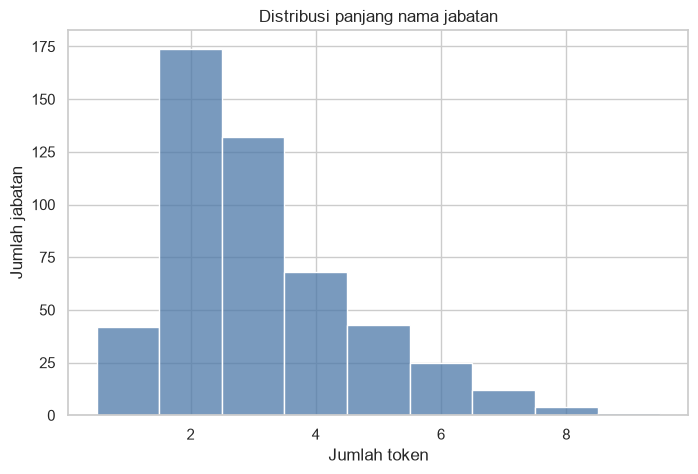

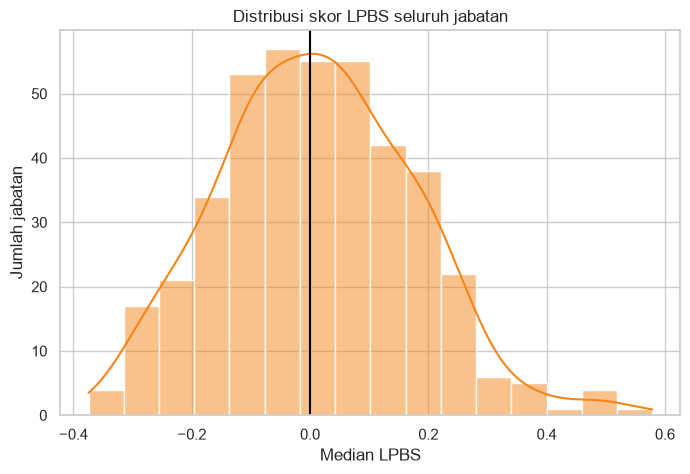

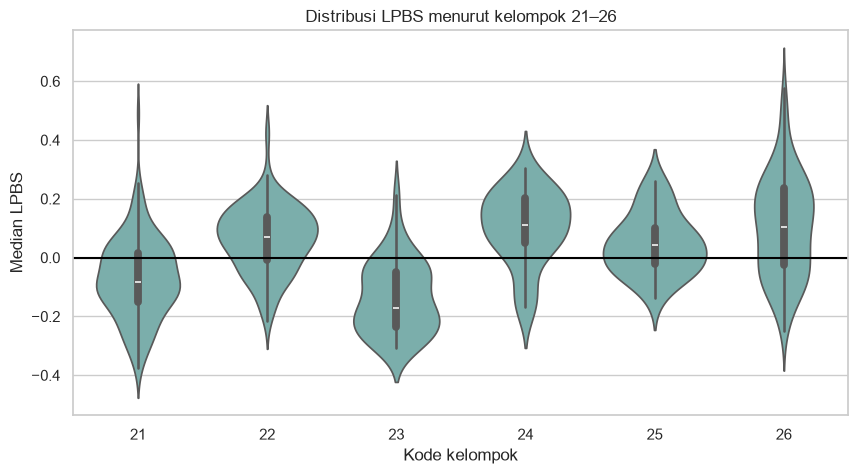

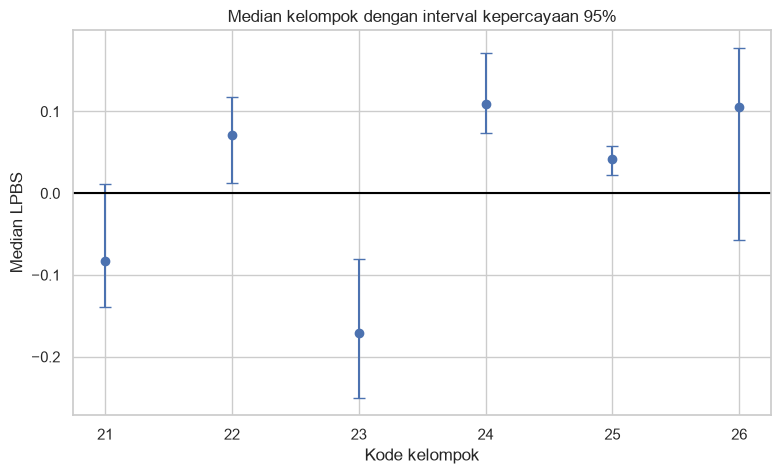

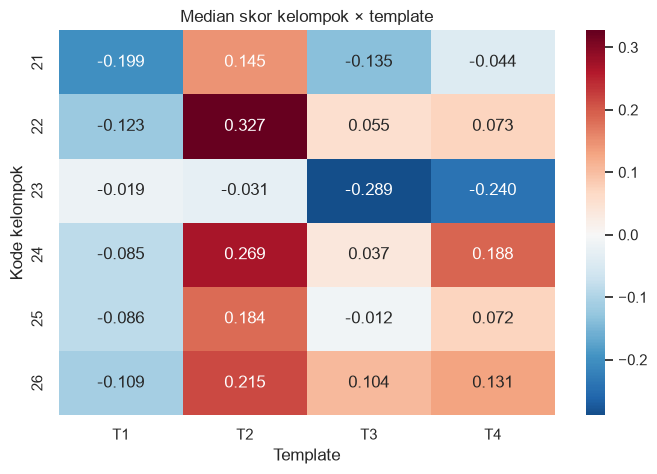

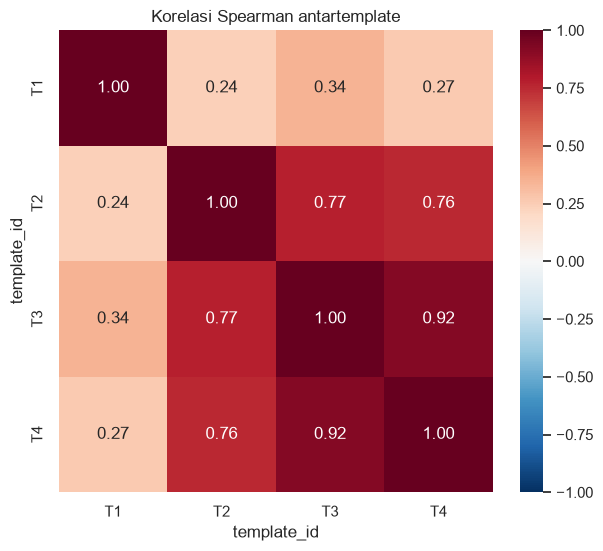

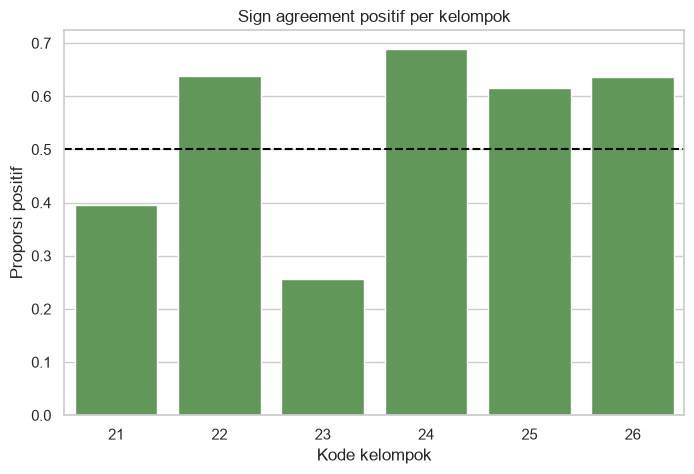

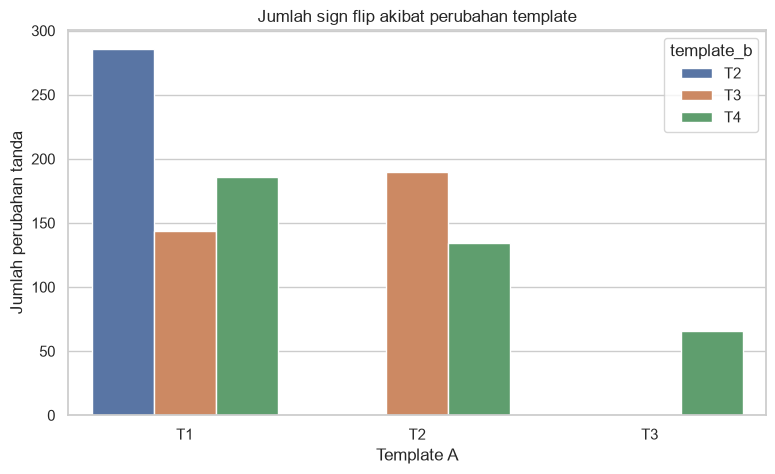

,occupation_code,occupation_name_raw,kbji_group_code,median_lpbs,sign_agreement
413,2659.07,Stand Up Komedian (Pelawak Tunggal),26,0.578463,1.00
406,2656.04,Penyiar Olahraga,26,0.504483,1.00
397,2654.05,Sutradara Panggung,26,0.496859,1.00
120,2164.03,Perencana Lalu Lintas,21,0.489350,1.00
392,2653.04,Penari Jalan,26,0.473480,0.75
181,2261.03,Asisten Bedah Gigi,22,0.423313,1.00
369,2642.05,Wartawan Olahraga,26,0.393610,1.00
371,2642.07,Reporter Berita TV/Radio,26,0.380281,1.00
368,2642.04,Reporter Surat Kabar,26,0.358763,1.00
404,2656.02,Penyiar Televisi,26,0.356748,1.00


,occupation_code,occupation_name_raw,kbji_group_code,median_lpbs,sign_agreement
15,2113.02,Ahli Kimia Organik,21,-0.374423,1.00
16,2113.03,Ahli Kimia Anorganik,21,-0.366076,1.00
25,2120.02,Ahli Matematika Terapan,21,-0.338624,0.75
17,2113.04,Ahli Kimia Fisika,21,-0.326901,1.00
33,2131.03,Ahli Biologi (Umum),21,-0.311669,1.00
234,2330.02,Guru Pendidikan Menengah Atas,23,-0.307469,1.00
14,2113.01,Ahli Kimia (Umum),21,-0.302664,1.00
235,2341.00,Guru Sekolah Dasar,23,-0.299335,1.00
214,2310.03,Dosen Ilmu Kedokteran dan Ilmu Hayati,23,-0.296850,0.75
233,2330.01,Guru Pendidikan Menengah Pertama,23,-0.293952,1.00


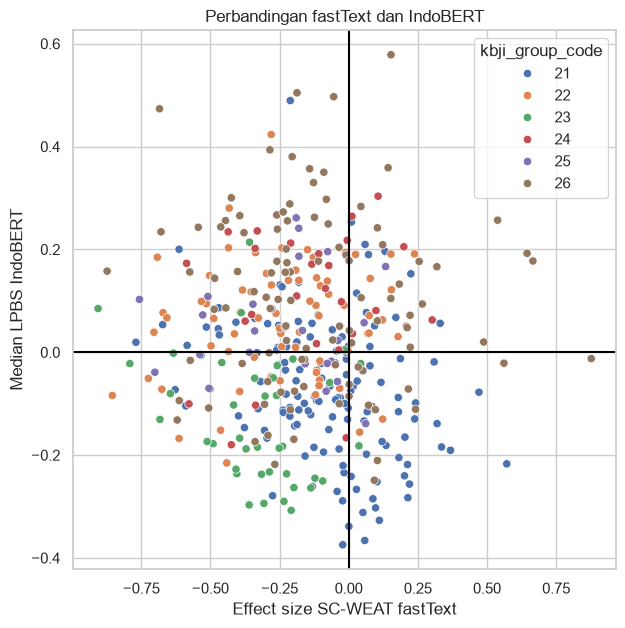

In [16]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5)); sns.histplot(df_all["observed_token_count"], discrete=True, color="#4C78A8"); plt.title("Distribusi panjang nama jabatan"); plt.xlabel("Jumlah token"); plt.ylabel("Jumlah jabatan"); plt.show()
plt.figure(figsize=(8, 5)); sns.histplot(occupation_summary["median_lpbs"], kde=True, color="#F58518"); plt.axvline(0, color="black"); plt.title("Distribusi skor LPBS seluruh jabatan"); plt.xlabel("Median LPBS"); plt.ylabel("Jumlah jabatan"); plt.show()
plt.figure(figsize=(10, 5)); sns.violinplot(data=occupation_summary, x="kbji_group_code", y="median_lpbs", inner="box", color="#72B7B2"); plt.axhline(0, color="black"); plt.title("Distribusi LPBS menurut kelompok 21–26"); plt.xlabel("Kode kelompok"); plt.ylabel("Median LPBS"); plt.show()
plt.figure(figsize=(9, 5)); plt.errorbar(group_summary["kbji_group_code"], group_summary["median_lpbs"], yerr=[group_summary["median_lpbs"] - group_summary["ci95_lower"], group_summary["ci95_upper"] - group_summary["median_lpbs"]], fmt="o", capsize=4); plt.axhline(0, color="black"); plt.title("Median kelompok dengan interval kepercayaan 95%"); plt.xlabel("Kode kelompok"); plt.ylabel("Median LPBS"); plt.show()
heat = main_long.groupby(["kbji_group_code", "template_id"])["lpbs_score"].median().unstack()
plt.figure(figsize=(8, 5)); sns.heatmap(heat, center=0, cmap="RdBu_r", annot=True, fmt=".3f"); plt.title("Median skor kelompok × template"); plt.xlabel("Template"); plt.ylabel("Kode kelompok"); plt.show()
plt.figure(figsize=(7, 6)); sns.heatmap(sign_matrix.corr(method="spearman"), vmin=-1, vmax=1, center=0, cmap="RdBu_r", annot=True, fmt=".2f"); plt.title("Korelasi Spearman antartemplate"); plt.show()
group_positive = main_long.assign(positive=main_long["lpbs_score"] > 0).groupby("kbji_group_code")["positive"].mean().reset_index(name="proporsi_positif")
plt.figure(figsize=(8, 5)); sns.barplot(data=group_positive, x="kbji_group_code", y="proporsi_positif", color="#59A14F"); plt.axhline(.5, color="black", linestyle="--"); plt.title("Sign agreement positif per kelompok"); plt.xlabel("Kode kelompok"); plt.ylabel("Proporsi positif"); plt.show()
flip_plot = template_stability[template_stability["analysis"].eq("pairwise_template")]
plt.figure(figsize=(9, 5)); sns.barplot(data=flip_plot, x="template_a", y="sign_flip_count", hue="template_b"); plt.title("Jumlah sign flip akibat perubahan template"); plt.xlabel("Template A"); plt.ylabel("Jumlah perubahan tanda"); plt.show()
display(occupation_summary.nlargest(15, "median_lpbs")[["occupation_code", "occupation_name_raw", "kbji_group_code", "median_lpbs", "sign_agreement"]])
display(occupation_summary.nsmallest(15, "median_lpbs")[["occupation_code", "occupation_name_raw", "kbji_group_code", "median_lpbs", "sign_agreement"]])
if len(fasttext_comparison):
    plt.figure(figsize=(7, 7)); sns.scatterplot(data=fasttext_comparison, x="fasttext_scweat_effect_size", y="median_lpbs", hue="kbji_group_code"); plt.axhline(0, color="black"); plt.axvline(0, color="black"); plt.title("Perbandingan fastText dan IndoBERT"); plt.xlabel("Effect size SC-WEAT fastText"); plt.ylabel("Median LPBS IndoBERT"); plt.show()


## 16. Interpretasi aktual dan kesimpulan

Teks berikut dibuat dari hasil yang baru dihitung. Interval kepercayaan dan sensitivitas menjadi bagian dari interpretasi, bukan hanya angka omnibus.


In [17]:
positive_share = float((occupation_summary["median_lpbs"] > 0).mean())
negative_share = float((occupation_summary["median_lpbs"] < 0).mean())
template_agreement = float(template_stability.loc[template_stability["analysis"].eq("pairwise_template"), "sign_agreement"].median())
lexical_rho = float(lexical_stats.loc[lexical_stats["metric"].eq("Spearman skor jabatan"), "value"].iloc[0])
group_text = "; ".join(f"{r.kbji_group_code}: median {r.median_lpbs:.4f}, CI95% [{r.ci95_lower:.4f}, {r.ci95_upper:.4f}]" for r in group_summary.itertuples())
display(Markdown(f"**Ringkasan aktual:** {len(occupation_summary)} jabatan dianalisis; proporsi median LPBS positif {positive_share:.3f} dan negatif {negative_share:.3f}. Kelompok: {group_text}. Median agreement tanda antartemplate {template_agreement:.3f}; korelasi Spearman kondisi utama dan sensitivitas istilah {lexical_rho:.3f}. Hasil ini menjawab distribusi asosiasi model dan perbedaan deskriptif kode 21–26, tetapi bukan fakta sosial. Stabilitas yang tidak sempurna menunjukkan ketergantungan pada formulasi kalimat atau istilah. Keterbatasan utama adalah satu model, template buatan, lexical set operasional, dependensi hierarkis, dan jarak antara intrinsic association dengan downstream behavior."))


**Ringkasan aktual:** 415 jabatan dianalisis; proporsi median LPBS positif 0.516 dan negatif 0.484. Kelompok: 21: median -0.0834, CI95% [-0.1390, 0.0116]; 22: median 0.0711, CI95% [0.0124, 0.1174]; 23: median -0.1704, CI95% [-0.2502, -0.0804]; 24: median 0.1094, CI95% [0.0733, 0.1721]; 25: median 0.0419, CI95% [0.0229, 0.0573]; 26: median 0.1053, CI95% [-0.0570, 0.1780]. Median agreement tanda antartemplate 0.602; korelasi Spearman kondisi utama dan sensitivitas istilah 0.247. Hasil ini menjawab distribusi asosiasi model dan perbedaan deskriptif kode 21–26, tetapi bukan fakta sosial. Stabilitas yang tidak sempurna menunjukkan ketergantungan pada formulasi kalimat atau istilah. Keterbatasan utama adalah satu model, template buatan, lexical set operasional, dependensi hierarkis, dan jarak antara intrinsic association dengan downstream behavior.

## Referensi metodologis

- Wilie et al. (2020), IndoNLU: https://aclanthology.org/2020.aacl-main.85/
- Model IndoBERT: https://huggingface.co/indobenchmark/indobert-base-p1
- Kurita et al. (2019), probability-based bias measurement: https://aclanthology.org/W19-3823/
- Husse dan Spitz (2022), sensitivitas pengukuran bias model kontekstual: https://aclanthology.org/2022.findings-emnlp.311/
- Goldfarb-Tarrant et al. (2021), batas intrinsic dan downstream bias: https://aclanthology.org/2021.acl-long.150/


## 17. Menyimpan output dan quality control final

Cell terakhir menyimpan semua tabel dan metadata, memeriksa file input, serta melakukan assertion. Tidak ada gambar yang disimpan.


In [18]:
outputs_to_save = {"test_v4_lpbs_scores_long.csv": lpbs_scores_long, "test_v4_lpbs_occupation_summary.csv": occupation_summary, "test_v4_lpbs_group_summary.csv": group_summary, "test_v4_lpbs_template_stability.csv": template_stability, "test_v4_lpbs_lexical_sensitivity.csv": lexical_sensitivity, "test_v4_lpbs_tokenization_audit.csv": tokenization_audit, "test_v4_lpbs_statistical_tests.csv": statistical_tests}
if len(fasttext_comparison):
    outputs_to_save["test_v4_lpbs_fasttext_comparison.csv"] = fasttext_comparison
    outputs_to_save["test_v4_lpbs_fasttext_group_comparison.csv"] = fasttext_group_comparison
for filename, frame in outputs_to_save.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False, encoding="utf-8")
input_hashes_after = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [analysis_path, all_path, gender_path]}
quality_rows = [
    {"check": "model sesuai", "status": MODEL_NAME == "indobenchmark/indobert-base-p1", "observed": MODEL_NAME},
    {"check": "kelompok 21-26 tercakup", "status": set(occupation_summary["kbji_group_code"].astype(str)) == allowed_groups, "observed": sorted(occupation_summary["kbji_group_code"].unique())},
    {"check": "empat template per jabatan", "status": bool((occupation_summary["valid_template_count"] == 4).all()), "observed": occupation_summary["valid_template_count"].value_counts().to_dict()},
    {"check": "jumlah baris long sesuai", "status": len(lpbs_scores_long) == len(df_analysis) * 4 * 2, "observed": len(lpbs_scores_long)},
    {"check": "tidak ada NaN atau tak hingga", "status": bool(np.isfinite(lpbs_scores_long.select_dtypes(include=np.number).to_numpy()).all()), "observed": int(lpbs_scores_long.isna().sum().sum())},
    {"check": "probabilitas 0 sampai 1", "status": bool(lpbs_scores_long[["male_probability_job", "female_probability_job", "male_probability_baseline", "female_probability_baseline"]].apply(lambda c: c.between(0, 1).all()).all()), "observed": "checked"},
    {"check": "tidak ada duplikat observasi", "status": bool(~lpbs_scores_long.duplicated(["occupation_code", "template_id", "gender_pair"]).any()), "observed": int(lpbs_scores_long.duplicated(["occupation_code", "template_id", "gender_pair"]).sum())},
    {"check": "baseline tiap template tersedia", "status": len(baseline_scores) == 4, "observed": len(baseline_scores)},
    {"check": "CSV input tidak berubah", "status": input_hashes_before == input_hashes_after, "observed": input_hashes_after},
]
quality_control = pd.DataFrame(quality_rows)
quality_control.to_csv(OUTPUT_DIR / "test_v4_lpbs_quality_control.csv", index=False, encoding="utf-8")
metadata = {"version": "test2_v4", "notebook": "test2_v4_indobert_lpbs_pipeline.ipynb", "model_name": MODEL_NAME, "model_revision": MODEL_REVISION, "tokenizer": tokenizer.__class__.__name__, "python_version": platform.python_version(), "pytorch_version": torch.__version__, "transformers_version": transformers.__version__, "scipy_version": scipy.__version__, "device": str(device), "cuda_available": torch.cuda.is_available(), "random_seed": RANDOM_SEED, "n_all_occupations": len(df_all), "n_analysis_occupations": len(df_analysis), "kbji_groups": sorted(allowed_groups), "templates": template_specs, "gender_pairs": gender_pair_specs, "aggregation": "median lintas empat template", "bootstrap_repetitions": BOOTSTRAP_REPETITIONS, "bootstrap_unit": "group_code tiga digit", "input_files": {"analysis": str(analysis_path), "all": str(all_path), "gender_csv": str(gender_path)}, "input_sha256_before": input_hashes_before, "input_sha256_after": input_hashes_after, "fasttext_baseline_available": bool(len(fasttext_comparison)), "time_start": TIME_START_ISO, "time_end": time.strftime("%Y-%m-%dT%H:%M:%S%z"), "duration_seconds": time.time() - TIME_START, "quality_control_passed": bool(quality_control["status"].all())}
(OUTPUT_DIR / "test_v4_run_metadata.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
display(quality_control)
display(pd.DataFrame({"output_file": sorted([p.name for p in OUTPUT_DIR.glob("test_v4_lpbs_*.csv")] + ["test_v4_run_metadata.json"])}))
assert quality_control["status"].all()
print("QC test_v4 LPBS lulus; durasi detik:", round(metadata["duration_seconds"], 2))


,check,status,observed
0,model sesuai,True,indobenchmark/indobert-base-p1
1,kelompok 21-26 tercakup,True,"[21, 22, 23, 24, 25, 26]"
2,empat template per jabatan,True,{4: 415}
3,jumlah baris long sesuai,True,3320
4,tidak ada NaN atau tak hingga,True,0
5,probabilitas 0 sampai 1,True,checked
6,tidak ada duplikat observasi,True,0
7,baseline tiap template tersedia,True,4
8,CSV input tidak berubah,True,{'data\test_v3_kbji_profesional_analysis.csv':...


,output_file
0,test_v4_lpbs_fasttext_comparison.csv
1,test_v4_lpbs_fasttext_group_comparison.csv
2,test_v4_lpbs_group_summary.csv
3,test_v4_lpbs_lexical_sensitivity.csv
4,test_v4_lpbs_occupation_summary.csv
5,test_v4_lpbs_quality_control.csv
6,test_v4_lpbs_scores_long.csv
7,test_v4_lpbs_statistical_tests.csv
8,test_v4_lpbs_template_stability.csv
9,test_v4_lpbs_tokenization_audit.csv


QC test_v4 LPBS lulus; durasi detik: 160.95
